<a href="https://colab.research.google.com/github/harpreetsingh171190-cmyk/weather-data-exploratory-analysis/blob/main/weather_data_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Weather Data Analysis with Pandas

**Author:** HARPREET SINGH  
**Portfolio focus:** Data Cleaning · Exploratory Data Analysis · Statistical Analysis · Visualization · Reproducible Reporting

## Project overview

This portfolio project analyzes a public **daily weather dataset** with the columns `location`, `date`, `precipitation`, `temp_max`, `temp_min`, `wind`, and `weather`. The source file is the Vega datasets `weather.csv` file, which contains observations for Seattle and New York across multiple years.

> **Dataset transparency:** This is a daily, 7-column dataset—not the separate hourly Canadian dataset with 8,784 rows. The notebook has been redesigned to match the actual schema so the analysis runs without renaming unrelated variables or inventing measurements.

## Questions explored

1. How complete and consistent is the dataset?
2. How do daily maximum and minimum temperatures vary by location and season?
3. Which weather categories are most common, and how does precipitation differ by category?
4. How are temperature, precipitation, and wind related?
5. Which observations are flagged by IQR screening or simple validity rules?
6. Do maximum temperatures differ across common weather categories?

## Project outputs

The notebook saves cleaned data, quality reports, statistical tables, a data-driven executive summary, and presentation-ready charts—including an optional 3D scatter plot—to the `outputs/` folder.

## 1. Setup, configuration, and data loading

Run the notebook from top to bottom. The first code cell downloads the public CSV if it is not already present. An internet connection is required for the first download.

In [ ]:


# ============================================================
# Project: Advanced Weather Data Analysis
# Author: HARPREET SINGH
# Purpose: Validate the current weather dataset
# ============================================================

import pandas as pd

required_columns = [
    "date",
    "precipitation",
    "temp_max",
    "temp_min",
    "wind",
    "weather",
]

# Display the actual columns before validation
print("Current columns:", df.columns.tolist())

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df_raw = df.copy()

print("\nSchema validation passed.")
print("Shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))

display(df.dtypes.rename("dtype").to_frame())
display(df.describe(include="all").T)

Current columns: ['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather']

Schema validation passed.
Shape: (1461, 6)
Duplicate rows: 0


,dtype
date,datetime64[ns]
precipitation,float64
temp_max,float64
temp_min,float64
wind,float64
weather,object


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,1461,NaN,NaN,NaN,2013-12-31 00:00:00,2012-01-01 00:00:00,2012-12-31 00:00:00,2013-12-31 00:00:00,2014-12-31 00:00:00,2015-12-31 00:00:00,NaN
precipitation,1461.0,NaN,NaN,NaN,3.029432,0.0,0.0,0.0,2.8,55.9,6.680194
temp_max,1461.0,NaN,NaN,NaN,16.439083,-1.6,10.6,15.6,22.2,35.6,7.349758
temp_min,1461.0,NaN,NaN,NaN,8.234771,-7.1,4.4,8.3,12.2,18.3,5.023004
wind,1461.0,NaN,NaN,NaN,3.241136,0.4,2.2,3.0,4.0,9.5,1.437825
weather,1461,5,rain,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Schema validation and initial exploration

The project validates the source columns before running analysis. This prevents a different weather dataset from silently producing misleading results.

In [ ]:
required_columns = [
    "location", "date", "precipitation", "temp_max",
    "temp_min", "wind", "weather"
]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(
        f"Dataset schema mismatch. Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Schema validation passed.")
print("Shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.dtypes.rename("dtype").to_frame())
display(df.describe(include="all").T)

Schema validation passed.
Shape: (1461, 6)
Duplicate rows: 0


,dtype
date,datetime64[ns]
precipitation,float64
temp_max,float64
temp_min,float64
wind,float64
weather,object


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,1461,NaN,NaN,NaN,2013-12-31 00:00:00,2012-01-01 00:00:00,2012-12-31 00:00:00,2013-12-31 00:00:00,2014-12-31 00:00:00,2015-12-31 00:00:00,NaN
precipitation,1461.0,NaN,NaN,NaN,3.029432,0.0,0.0,0.0,2.8,55.9,6.680194
temp_max,1461.0,NaN,NaN,NaN,16.439083,-1.6,10.6,15.6,22.2,35.6,7.349758
temp_min,1461.0,NaN,NaN,NaN,8.234771,-7.1,4.4,8.3,12.2,18.3,5.023004
wind,1461.0,NaN,NaN,NaN,3.241136,0.4,2.2,3.0,4.0,9.5,1.437825
weather,1461,5,rain,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Export a first-pass missingness report before cleaning.
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values("missing_pct", ascending=False)

display(missing_report)
missing_report.to_csv(TABLE_DIR / "missingness_report_before_cleaning.csv")

,missing_count,missing_pct,dtype
date,0,0.0,datetime64[ns]
precipitation,0,0.0,float64
temp_max,0,0.0,float64
temp_min,0,0.0,float64
wind,0,0.0,float64
weather,0,0.0,object


### Initial quality review

- Confirm that the dataset contains the expected 7 columns.
- Check whether dates and numeric measurements are parsed correctly.
- Missing values are reported rather than silently removed.
- The dataset has multiple locations, so time-based comparisons should retain the `location` dimension.

## 3. Data cleaning and validation

Whitespace is trimmed from column names and text fields. Dates and numeric measurements are parsed explicitly. Exact duplicates are removed, while missing values remain available for transparent reporting.

In [ ]:


# Normalize column names by trimming whitespace only.
df.columns = df.columns.astype(str).str.strip()

required_columns = [
    "date", "precipitation", "temp_max",
    "temp_min", "wind", "weather"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Expected columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Parse dates and numeric measurements; invalid values become missing and are counted.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_columns = ["precipitation", "temp_max", "temp_min", "wind"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["weather"] = (
    df["weather"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

invalid_date_count = int(df["date"].isna().sum())
duplicate_count = int(df.duplicated().sum())

cleaning_log = {
    "rows_at_start": len(df_raw),
    "invalid_dates": invalid_date_count,
    "duplicate_rows_detected": duplicate_count,
    "rows_before_drop_duplicates": len(df),
}

# Remove exact duplicate records only.
df = df.drop_duplicates().copy()
cleaning_log["rows_after_drop_duplicates"] = len(df)

# Diagnostic validity checks; flagged rows are not automatically deleted.
range_checks = {
    "negative_precipitation": (
        (df["precipitation"] < 0)
        & df["precipitation"].notna()
    ),
    "negative_wind_speed": (
        (df["wind"] < 0)
        & df["wind"].notna()
    ),
    "minimum_temperature_above_maximum": (
        (df["temp_min"] > df["temp_max"])
        & df[["temp_min", "temp_max"]].notna().all(axis=1)
    ),
}

for check_name, mask in range_checks.items():
    cleaning_log[check_name] = int(mask.sum())

display(pd.Series(cleaning_log, name="count").to_frame())
display(df.head())

,count
rows_at_start,1461
invalid_dates,0
duplicate_rows_detected,0
rows_before_drop_duplicates,1461
rows_after_drop_duplicates,1461
negative_precipitation,0
negative_wind_speed,0
minimum_temperature_above_maximum,0


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


**Cleaning policy:** Only exact duplicate rows are removed automatically. Negative precipitation/wind values and inconsistent minimum/maximum temperatures are flagged for review rather than silently deleted. IQR outliers are treated as candidates for investigation, not proof of bad data.

## 4. Time coverage and data quality

In [ ]:


valid_dates = df["date"].dropna()

if not valid_dates.empty:
    print("First date:", valid_dates.min())
    print("Last date: ", valid_dates.max())
    print("Unique dates:", df["date"].nunique())

    if "location" in df.columns:
        print(
            "Locations:",
            sorted(
                df["location"]
                .dropna()
                .astype(str)
                .unique()
                .tolist()
            )
        )
    else:
        print("Locations: Not available in this dataset.")

else:
    warnings.warn(
        "No valid dates were parsed; time-based analysis will be skipped."
    )

quality_summary = pd.DataFrame({
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
})

display(quality_summary)

quality_summary.to_csv(
    TABLE_DIR / "data_quality_summary.csv",
    index=True
)

print("Data quality summary saved successfully.")

First date: 2012-01-01 00:00:00
Last date:  2015-12-31 00:00:00
Unique dates: 1461
Locations: Not available in this dataset.


,non_null,missing,missing_pct
date,1461,0,0.0
precipitation,1461,0,0.0
temp_max,1461,0,0.0
temp_min,1461,0,0.0
wind,1461,0,0.0
weather,1461,0,0.0


Data quality summary saved successfully.


## 5. Univariate analysis and distributions

Daily maximum/minimum temperature, precipitation, and wind are analyzed using descriptive statistics and histograms.

,count,mean,std,min,25%,50%,75%,max
precipitation,1461.0,3.029432,6.680194,0.0,0.0,0.0,2.8,55.9
temp_max,1461.0,16.439083,7.349758,-1.6,10.6,15.6,22.2,35.6
temp_min,1461.0,8.234771,5.023004,-7.1,4.4,8.3,12.2,18.3
wind,1461.0,3.241136,1.437825,0.4,2.2,3.0,4.0,9.5


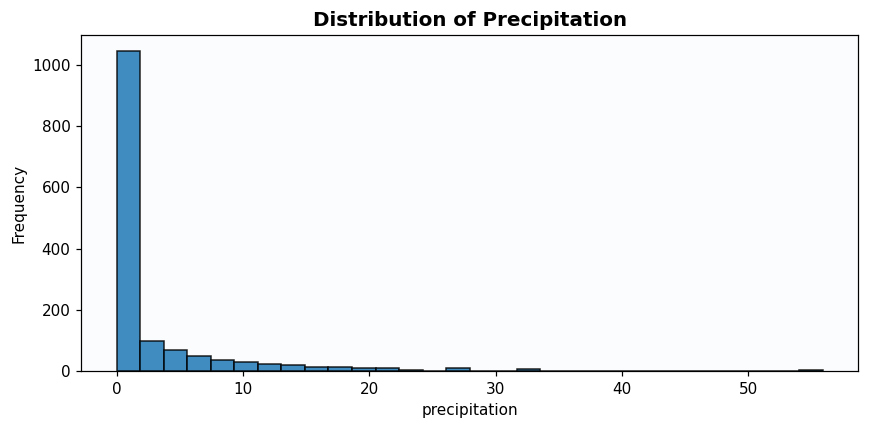

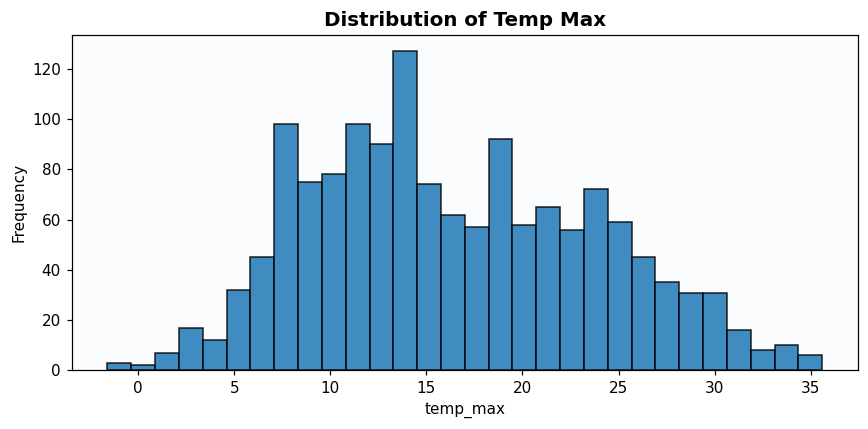

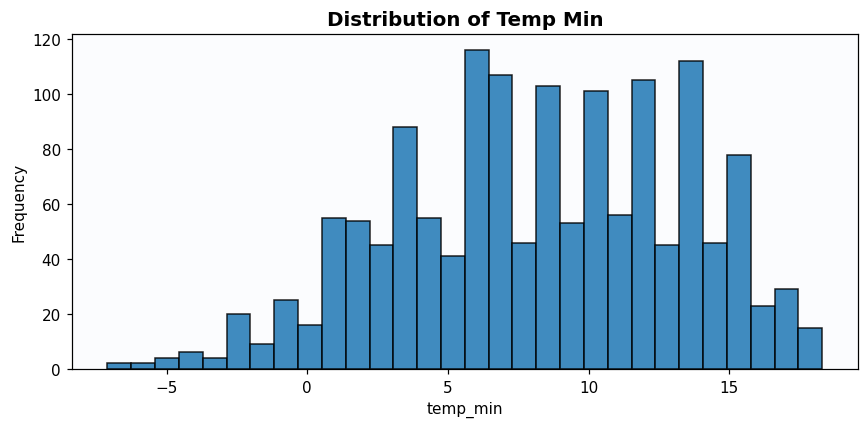

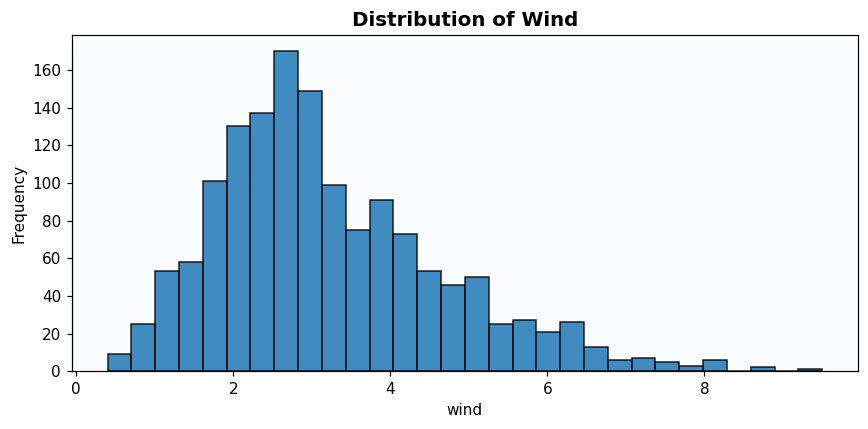

In [ ]:
numeric_present = [column for column in numeric_columns if column in df.columns]
display(df[numeric_present].describe().T)

for column in numeric_present:
    values = df[column].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(values, bins=30, edgecolor="black", alpha=0.85)
    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"distribution_{column}.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 6. Weather category and location analysis

,weather,count,percentage
0,rain,641,43.87
1,sun,640,43.81
2,fog,101,6.91
3,drizzle,53,3.63
4,snow,26,1.78


Location analysis skipped: the dataset does not contain a 'location' column.


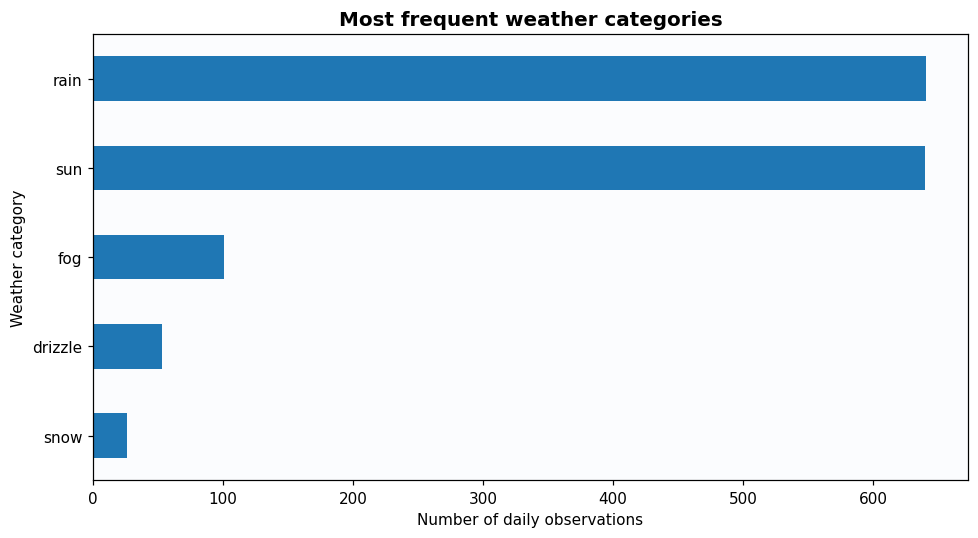

In [ ]:


# Count weather categories and calculate percentages.
weather_counts = (
    df["weather"]
    .value_counts(dropna=False)
    .rename_axis("weather")
    .reset_index(name="count")
)

weather_counts["percentage"] = (
    weather_counts["count"] / len(df) * 100
).round(2)

display(weather_counts)

weather_counts.to_csv(
    TABLE_DIR / "weather_category_counts.csv",
    index=False
)

# Count records by location only if the column exists.
if "location" in df.columns:
    location_counts = (
        df["location"]
        .value_counts(dropna=False)
        .rename_axis("location")
        .reset_index(name="count")
    )

    display(location_counts)

    location_counts.to_csv(
        TABLE_DIR / "location_record_counts.csv",
        index=False
    )
else:
    print(
        "Location analysis skipped: "
        "the dataset does not contain a 'location' column."
    )

# Plot the most frequent weather categories.
top_weather = (
    df["weather"]
    .value_counts()
    .head(TOP_WEATHER_CATEGORIES)
    .sort_values()
)

if not top_weather.empty:
    fig, ax = plt.subplots(figsize=(9, 5))

    top_weather.plot(kind="barh", ax=ax)

    ax.set_title("Most frequent weather categories")
    ax.set_xlabel("Number of daily observations")
    ax.set_ylabel("Weather category")

    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / "weather_category_frequency.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

## 7. Time-series analysis by location

Daily observations are plotted over time. The source already contains daily records, so no hourly-to-daily aggregation is needed.

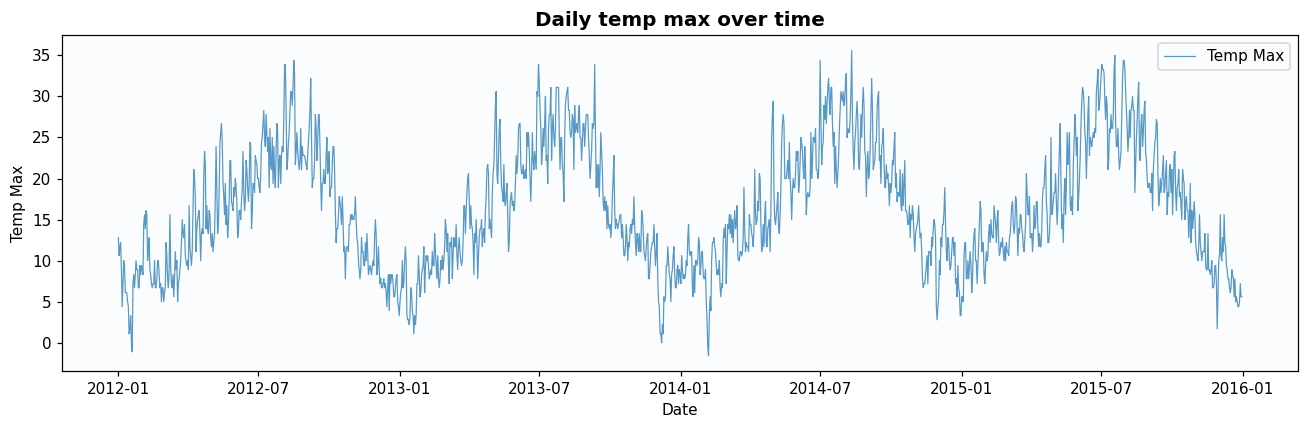

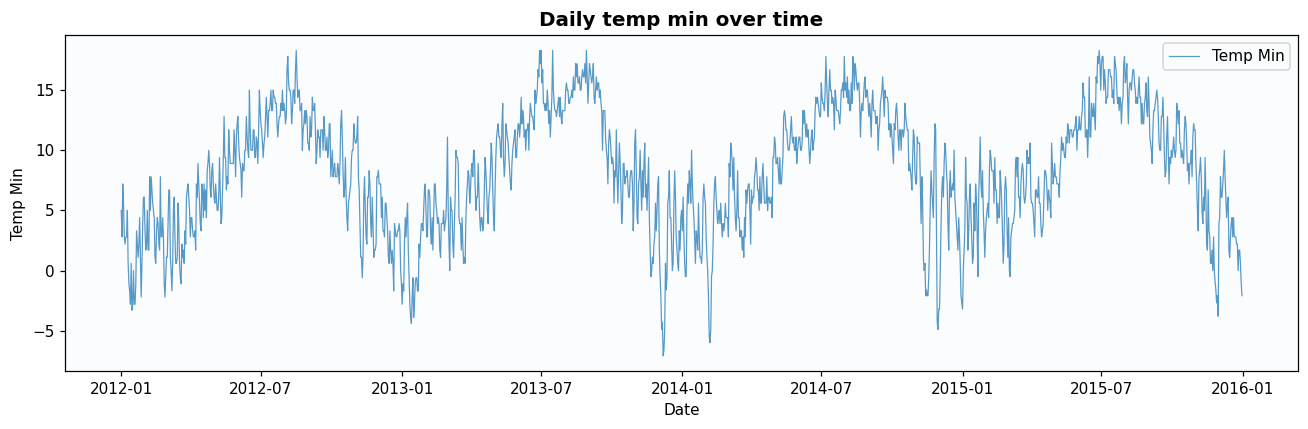

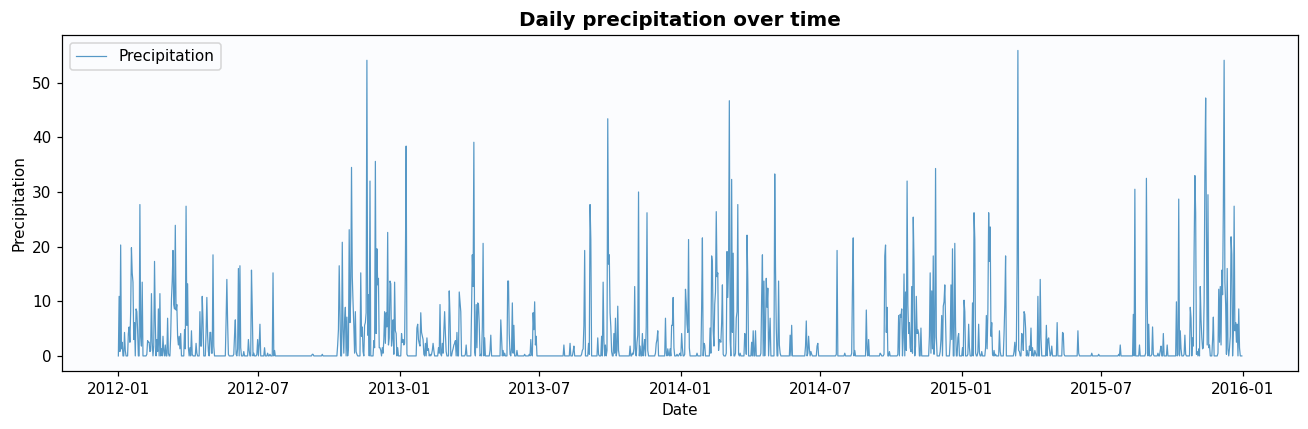

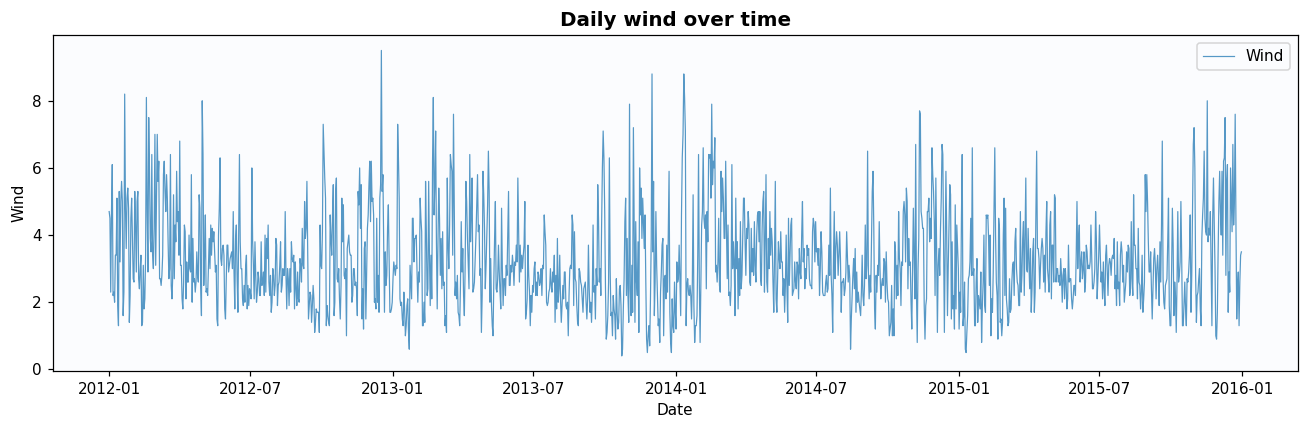

,date,temp_max,temp_min,precipitation,wind
0,2012-01-01,7.054839,1.541935,5.590323,3.900000
1,2012-02-01,9.275862,3.203448,3.182759,3.903448
2,2012-03-01,9.554839,2.838710,5.903226,4.248387
3,2012-04-01,14.873333,5.993333,2.270000,3.373333
4,2012-05-01,17.661290,8.190323,1.683871,3.354839


Monthly summary saved successfully.


In [ ]:


# Prepare time-series data using valid dates.
time_df = (
    df.dropna(subset=["date"])
    .sort_values("date")
    .copy()
)

if not time_df.empty:
    # Create time-series charts for available numeric metrics.
    for metric in ["temp_max", "temp_min", "precipitation", "wind"]:
        if metric not in time_df.columns:
            continue

        fig, ax = plt.subplots(figsize=(12, 4))

        ax.plot(
            time_df["date"],
            time_df[metric],
            linewidth=0.8,
            alpha=0.75,
            label=metric.replace("_", " ").title()
        )

        ax.set_title(f"Daily {metric.replace('_', ' ')} over time")
        ax.set_xlabel("Date")
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.legend()
        fig.tight_layout()

        fig.savefig(
            FIGURE_DIR / f"timeseries_{metric}.png",
            dpi=FIGURE_DPI,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # Calculate monthly averages without a location column.
    numeric_present = [
        column
        for column in ["temp_max", "temp_min", "precipitation", "wind"]
        if column in time_df.columns
    ]

    if numeric_present:
        daily_summary = (
            time_df
            .set_index("date")[numeric_present]
            .resample("MS")
            .mean()
            .reset_index()
        )

        display(daily_summary.head())

        daily_summary.to_csv(
            TABLE_DIR / "monthly_means.csv",
            index=False
        )

        print("Monthly summary saved successfully.")

else:
    print(
        "Skipping time-series charts because "
        "no valid dates are available."
    )

## 8. Seasonal patterns

The month and year are derived from the date field. Monthly temperature summaries are compared across locations.

,month,temp_max,temp_min
0,1,8.229032,2.696774
1,2,9.860177,4.054867
2,3,12.387097,4.858871
3,4,15.020000,6.362500
4,5,19.295968,9.614516
5,6,22.400000,12.244167
6,7,25.998387,14.197581
7,8,26.112097,14.769355
8,9,21.924167,12.358333
9,10,16.389516,9.350806


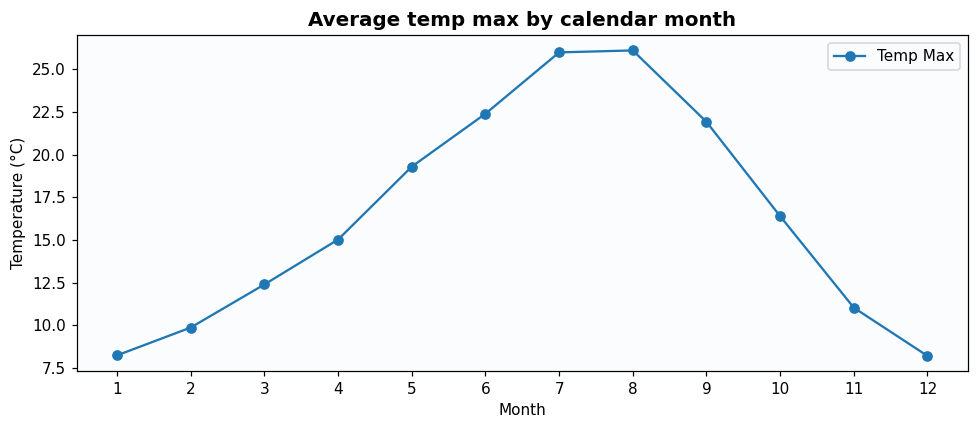

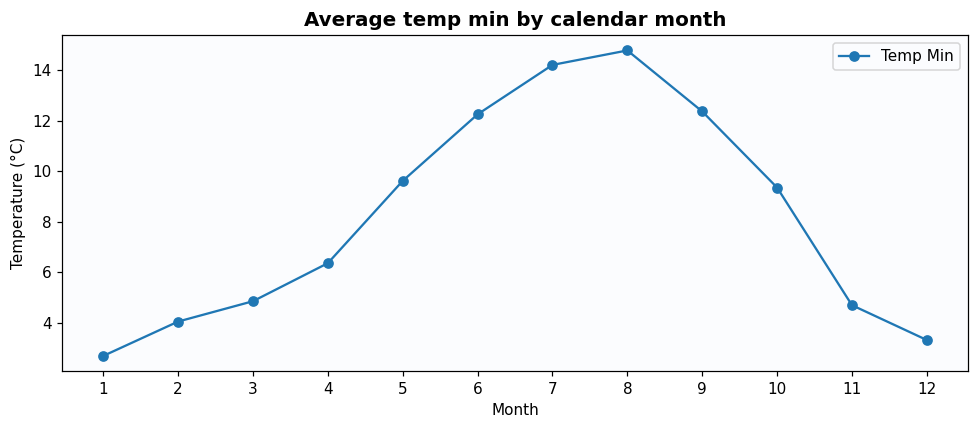

In [ ]:


# Analyze average temperatures by calendar month.
if not time_df.empty:
    enriched = time_df.copy()

    enriched["year"] = enriched["date"].dt.year
    enriched["month"] = enriched["date"].dt.month
    enriched["month_name"] = enriched["date"].dt.month_name()

    # Calculate average temperatures for each calendar month.
    monthly_temperature = (
        enriched.groupby("month", as_index=False)[
            ["temp_max", "temp_min"]
        ]
        .mean()
        .sort_values("month")
    )

    display(monthly_temperature.head(12))

    monthly_temperature.to_csv(
        TABLE_DIR / "monthly_temperature.csv",
        index=False
    )

    # Plot average temperatures by calendar month.
    for metric in ["temp_max", "temp_min"]:
        fig, ax = plt.subplots(figsize=(9, 4))

        ax.plot(
            monthly_temperature["month"],
            monthly_temperature[metric],
            marker="o",
            label=metric.replace("_", " ").title()
        )

        ax.set_title(
            f"Average {metric.replace('_', ' ')} by calendar month"
        )
        ax.set_xlabel("Month")
        ax.set_ylabel("Temperature (°C)")
        ax.set_xticks(range(1, 13))
        ax.legend()
        fig.tight_layout()

        fig.savefig(
            FIGURE_DIR / f"seasonal_{metric}.png",
            dpi=FIGURE_DPI,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

else:
    print("Skipping seasonal analysis because no valid dates are available.")

## 9. Correlation and relationships

Pearson correlation is used for an exploratory look at linear relationships between numeric variables. Correlation does not establish causation.

,temp_max,temp_min,precipitation,wind
temp_max,1.000,0.876,-0.229,-0.165
temp_min,0.876,1.000,-0.073,-0.074
precipitation,-0.229,-0.073,1.000,0.328
wind,-0.165,-0.074,0.328,1.000


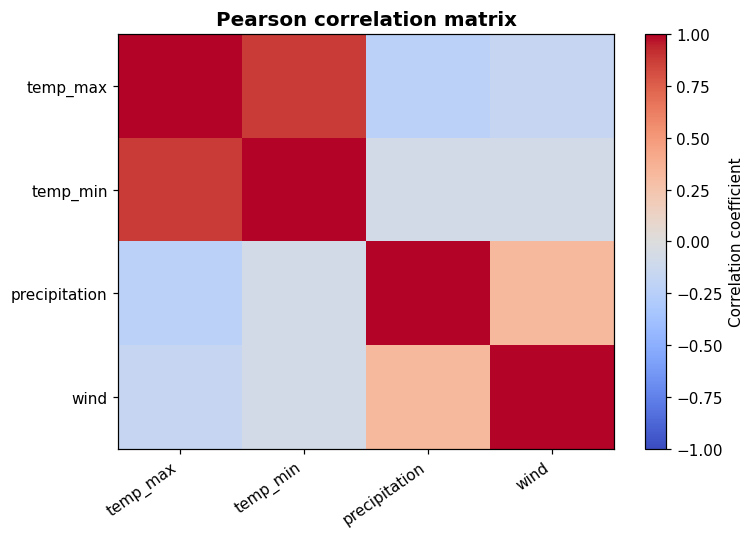

precipitation                wind               temp_max                temp_min              
                count   mean median count   mean median    count    mean median    count   mean median
weather                                                                                               
drizzle            53  0.000   0.00    53  2.368   2.10       53  15.926   16.1       53  7.111    8.3
fog               101  0.000   0.00   101  2.481   2.40      101  16.757   16.1      101  7.979    8.3
rain              641  6.558   3.30   641  3.670   3.40      641  13.455   12.8      641  7.589    7.2
snow               26  8.554   5.45    26  4.412   4.95       26   5.573    5.6       26  0.146    0.6
sun               640  0.000   0.00   640  2.956   2.80      640  19.862   21.1      640  9.344   10.6

In [ ]:
corr = df[numeric_present].corr(method="pearson", min_periods=2)
display(corr.round(3))
corr.to_csv(TABLE_DIR / "numeric_correlation_matrix.csv")

if not corr.empty:
    fig, ax = plt.subplots(figsize=(7, 5))
    image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto", cmap="coolwarm")
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title("Pearson correlation matrix")
    fig.colorbar(image, ax=ax, label="Correlation coefficient")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "correlation_matrix.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Compare precipitation and wind by weather category.
weather_metric_summary = df.groupby("weather", dropna=False)[["precipitation", "wind", "temp_max", "temp_min"]].agg(["count", "mean", "median"])
display(weather_metric_summary.round(3))
weather_metric_summary.to_csv(TABLE_DIR / "weather_metric_summary.csv")

## 10. Outlier screening with the IQR rule

The 1.5 × IQR rule identifies values outside conventional fences. Weather extremes can be genuine, so these records are not removed automatically.

In [ ]:
outlier_rows = []
for column in numeric_present:
    series = df[column].dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[column] < lower) | (df[column] > upper)
    outlier_rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct_of_nonmissing": round(mask.sum() / series.size * 100, 2),
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(TABLE_DIR / "iqr_outlier_report.csv", index=False)

,column,q1,q3,iqr,lower_fence,upper_fence,outlier_count,outlier_pct_of_nonmissing
0,temp_max,10.6,22.2,11.6,-6.8,39.6,0,0.00
1,temp_min,4.4,12.2,7.8,-7.3,23.9,0,0.00
2,precipitation,0.0,2.8,2.8,-4.2,7.0,206,14.10
3,wind,2.2,4.0,1.8,-0.5,6.7,34,2.33


## 11. Descriptive statistics and group comparison

In [ ]:
stats = df[numeric_present].agg(["count", "mean", "median", "std", "min", "max"]).T
stats["skew"] = df[numeric_present].skew(numeric_only=True)
display(stats.round(3))
stats.to_csv(TABLE_DIR / "descriptive_statistics.csv")

# Summarize maximum temperature by the most common weather labels.
common_labels = df["weather"].value_counts().head(TOP_WEATHER_CATEGORIES).index
group_df = df[df["weather"].isin(common_labels)].dropna(subset=["temp_max", "weather"])
group_summary = (
    group_df.groupby("weather")["temp_max"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)
display(group_summary.round(3))
group_summary.to_csv(TABLE_DIR / "maximum_temperature_by_weather.csv")

,count,mean,median,std,min,max,skew
temp_max,1461.0,16.439,15.6,7.350,-1.6,35.6,0.281
temp_min,1461.0,8.235,8.3,5.023,-7.1,18.3,-0.249
precipitation,1461.0,3.029,0.0,6.680,0.0,55.9,3.506
wind,1461.0,3.241,3.0,1.438,0.4,9.5,0.892


,count,mean,median,std
weather,,,,
rain,641,13.455,12.8,4.973
sun,640,19.862,21.1,7.698
fog,101,16.757,16.1,6.775
drizzle,53,15.926,16.1,8.812
snow,26,5.573,5.6,3.109


## 12. Optional inferential test: maximum temperature by weather category

The Kruskal–Wallis test is a non-parametric exploratory test. The daily observations may not be fully independent because weather is temporally correlated; interpret results cautiously and do not treat a p-value as a measure of practical importance.

In [ ]:
try:
    from scipy.stats import kruskal

    counts = df.groupby("weather")["temp_max"].count()
    selected_labels = counts[counts >= MIN_GROUP_SIZE_FOR_TEST].nlargest(TOP_WEATHER_CATEGORIES).index
    groups = [
        df.loc[df["weather"] == label, "temp_max"].dropna().to_numpy()
        for label in selected_labels
    ]
    groups = [group for group in groups if len(group) >= MIN_GROUP_SIZE_FOR_TEST]

    if len(groups) >= 2:
        statistic, p_value = kruskal(*groups)
        print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
        print(f"p-value: {p_value:.6g}")
        print("Interpretation: a small p-value suggests that at least one selected weather category differs in its maximum-temperature distribution.")
    else:
        print("Not enough weather categories meet the minimum group size for this test.")
except ImportError:
    print("SciPy is not installed. Install it with: %pip install scipy")

Kruskal-Wallis H statistic: 298.5301
p-value: 2.24841e-63
Interpretation: a small p-value suggests that at least one selected weather category differs in its maximum-temperature distribution.


## 13. Export cleaned data and project outputs

In [ ]:


# Save the cleaned dataset.
cleaned_path = OUTPUT_DIR / "weather_cleaned.csv"
df.to_csv(cleaned_path, index=False)

# Create a summary of the analysis run.
run_summary = {
    "author": AUTHOR,
    "source_file": str(DATA_PATH),
    "rows_after_cleaning": int(len(df)),
    "columns": int(df.shape[1]),
    "valid_dates": int(df["date"].notna().sum()),
    "date_min": (
        str(df["date"].min())
        if df["date"].notna().any()
        else None
    ),
    "date_max": (
        str(df["date"].max())
        if df["date"].notna().any()
        else None
    ),
    "total_missing_cells": int(df.isna().sum().sum()),
}

# Include location information only if the column exists.
if "location" in df.columns:
    run_summary["locations"] = sorted(
        df["location"].dropna().astype(str).unique().tolist()
    )
else:
    run_summary["locations"] = "Not available in dataset"

# Save the run summary.
pd.Series(run_summary, name="value").to_csv(
    TABLE_DIR / "run_summary.csv"
)

print("Saved cleaned data:", cleaned_path.resolve())
print("Saved tables to:", TABLE_DIR.resolve())
print("Saved figures to:", FIGURE_DIR.resolve())
print("Run summary saved successfully.")

Saved cleaned data: /content/outputs/weather_cleaned.csv
Saved tables to: /content/outputs/tables
Saved figures to: /content/outputs/figures
Run summary saved successfully.


## 14. Professional visual analytics studio

These presentation-ready plots are saved to `outputs/figures/`. The 3D plot uses only columns that exist in the selected dataset.

Missingness plot skipped: no missing values found.
Saved: outputs/figures/minimum_vs_maximum_temperature_hexbin.png


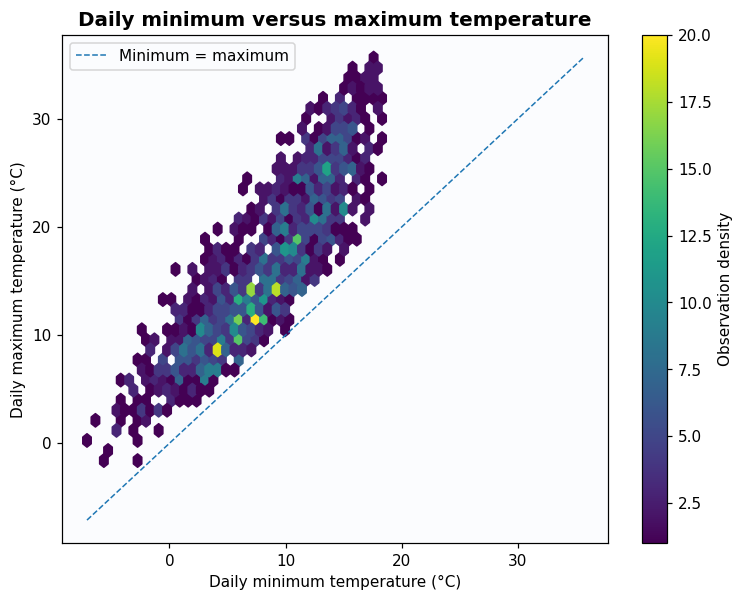

Saved: outputs/figures/numeric_scatter_matrix.png


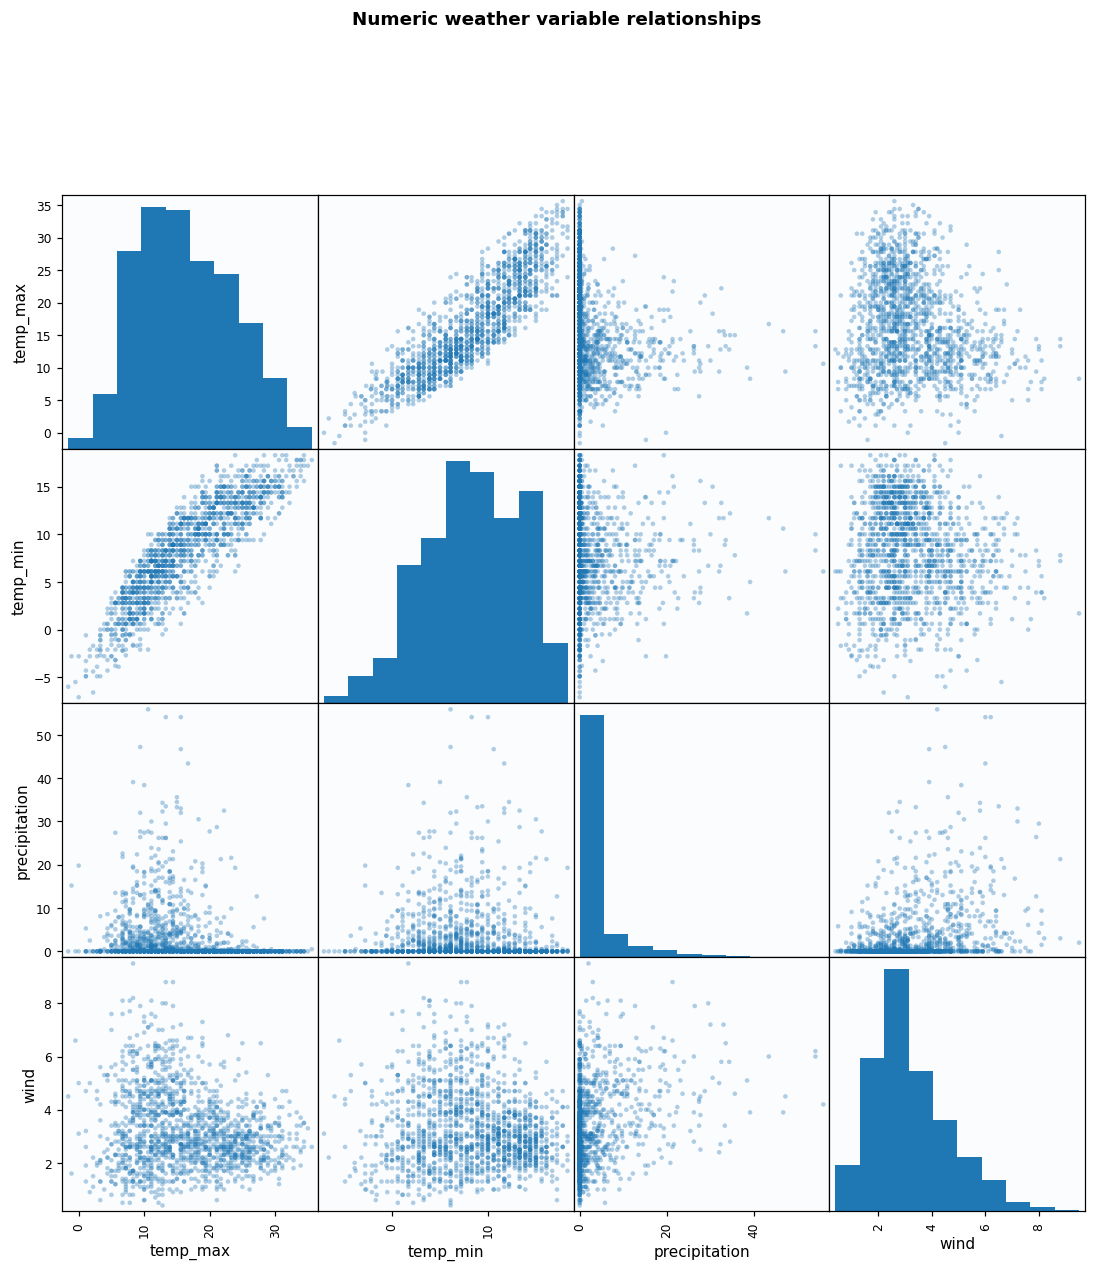

/tmp/ipykernel_776/1278332997.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(arrays, vert=False, labels=list(order), showfliers=False, patch_artist=True)


Saved: outputs/figures/maximum_temperature_by_weather_boxplot.png


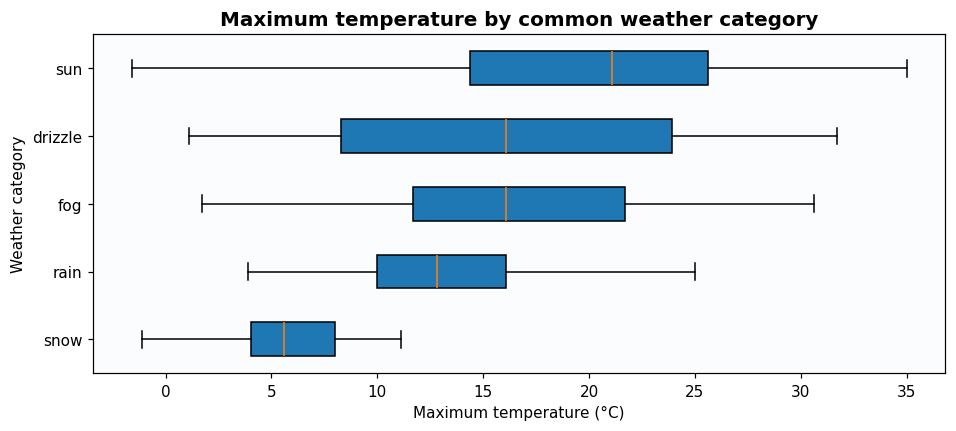

Saved: outputs/figures/correlation_heatmap_annotated.png


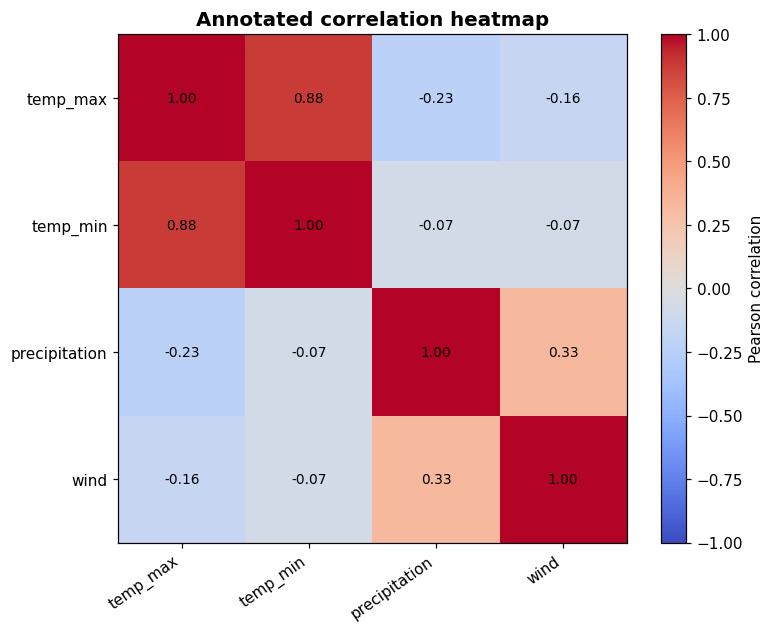

Saved: outputs/figures/weather_feature_space_3d.png


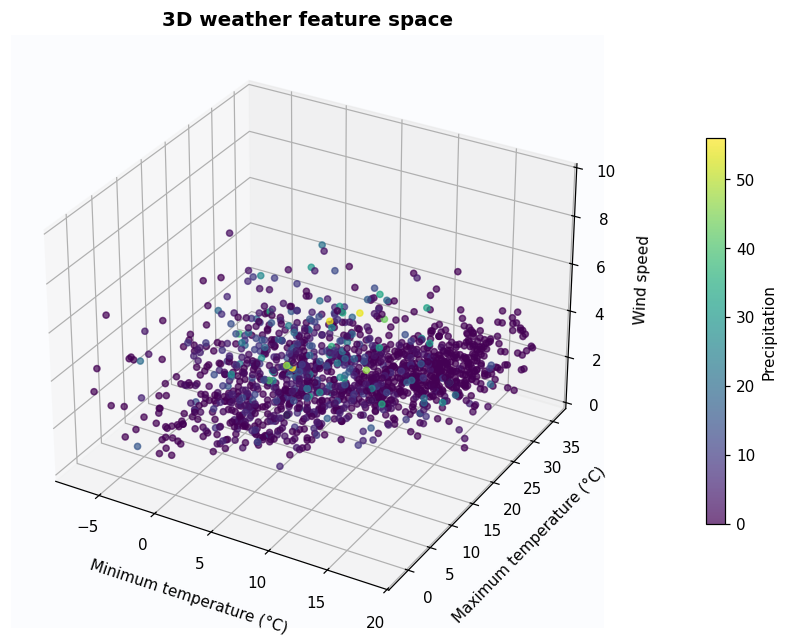

In [ ]:
def save_figure(fig, filename):
    """Save a figure consistently and return its output path."""
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
    print(f"Saved: {path}")
    return path

# 1. Missingness pattern
missing_cols = [column for column in df.columns if df[column].isna().any()]
if missing_cols:
    sample = df[missing_cols].head(500).isna().astype(int)
    fig, ax = plt.subplots(figsize=(max(8, len(missing_cols) * 0.8), 4))
    ax.imshow(sample.T, aspect="auto", interpolation="nearest", cmap="magma")
    ax.set_yticks(range(len(missing_cols)), labels=missing_cols)
    ax.set_xlabel("Row sample (up to first 500 rows)")
    ax.set_title("Missing-value pattern (bright = missing)")
    save_figure(fig, "missingness_pattern.png")
    plt.show()
    plt.close(fig)
else:
    print("Missingness plot skipped: no missing values found.")

# 2. Maximum versus minimum temperature
pair = df[["temp_max", "temp_min"]].dropna()
if not pair.empty:
    fig, ax = plt.subplots(figsize=(8, 6))
    hb = ax.hexbin(pair["temp_min"], pair["temp_max"], gridsize=35, mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=ax, label="Observation density")
    low = min(pair.min())
    high = max(pair.max())
    ax.plot([low, high], [low, high], linestyle="--", linewidth=1, label="Minimum = maximum")
    ax.set_xlabel("Daily minimum temperature (°C)")
    ax.set_ylabel("Daily maximum temperature (°C)")
    ax.set_title("Daily minimum versus maximum temperature")
    ax.legend()
    save_figure(fig, "minimum_vs_maximum_temperature_hexbin.png")
    plt.show()
    plt.close(fig)

# 3. Numeric scatter matrix
pair_cols = [column for column in numeric_present if column in df.columns]
sample_df = df[pair_cols].dropna()
if len(pair_cols) >= 2 and not sample_df.empty:
    if len(sample_df) > 2500:
        sample_df = sample_df.sample(2500, random_state=RANDOM_SEED)
    axes = pd.plotting.scatter_matrix(sample_df, figsize=(12, 12), diagonal="hist", alpha=0.35)
    fig = axes[0, 0].figure
    fig.suptitle("Numeric weather variable relationships", y=1.02, fontweight="bold")
    save_figure(fig, "numeric_scatter_matrix.png")
    plt.show()
    plt.close(fig)

# 4. Maximum temperature by weather category
labels = df["weather"].value_counts().head(TOP_WEATHER_CATEGORIES).index
plot_df = df[df["weather"].isin(labels)].dropna(subset=["weather", "temp_max"])
if not plot_df.empty:
    order = plot_df.groupby("weather")["temp_max"].median().sort_values().index
    arrays = [plot_df.loc[plot_df["weather"] == label, "temp_max"].to_numpy() for label in order]
    fig, ax = plt.subplots(figsize=(10, max(4, len(order) * 0.55)))
    ax.boxplot(arrays, vert=False, labels=list(order), showfliers=False, patch_artist=True)
    ax.set_title("Maximum temperature by common weather category")
    ax.set_xlabel("Maximum temperature (°C)")
    ax.set_ylabel("Weather category")
    save_figure(fig, "maximum_temperature_by_weather_boxplot.png")
    plt.show()
    plt.close(fig)

# 5. Annotated correlation heatmap
if len(pair_cols) >= 2:
    corr_plot = df[pair_cols].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(corr_plot, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(corr_plot.columns)), labels=corr_plot.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(corr_plot.index)), labels=corr_plot.index)
    for row in range(len(corr_plot.index)):
        for column in range(len(corr_plot.columns)):
            value = corr_plot.iloc[row, column]
            if pd.notna(value):
                ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title("Annotated correlation heatmap")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    save_figure(fig, "correlation_heatmap_annotated.png")
    plt.show()
    plt.close(fig)

# 6. Optional 3D scatter plot: minimum temperature, maximum temperature, and wind.
if MAKE_3D_PLOTS:
    columns_3d = ["temp_min", "temp_max", "wind", "precipitation"]
    cloud = df[columns_3d].dropna()
    if len(cloud) > 4000:
        cloud = cloud.sample(4000, random_state=RANDOM_SEED)
    if len(cloud) >= 10:
        fig = plt.figure(figsize=(10, 7))
        ax = fig.add_subplot(111, projection="3d")
        scatter = ax.scatter(
            cloud["temp_min"], cloud["temp_max"], cloud["wind"],
            c=cloud["precipitation"], cmap="viridis", s=16, alpha=0.7, depthshade=True
        )
        ax.set_xlabel("Minimum temperature (°C)", labelpad=8)
        ax.set_ylabel("Maximum temperature (°C)", labelpad=8)
        ax.set_zlabel("Wind speed", labelpad=8)
        ax.set_title("3D weather feature space")
        fig.colorbar(scatter, ax=ax, pad=0.12, shrink=0.65, label="Precipitation")
        save_figure(fig, "weather_feature_space_3d.png")
        plt.show()
        plt.close(fig)
    else:
        print("3D plot skipped: fewer than 10 complete records.")

## 15. Executive summary generated from the data

Review the summary after running the notebook. It is generated from the current dataset rather than hard-coded example results.

In [ ]:


# Generate the executive summary.
summary_lines = [
    f"Dataset contains {len(df):,} rows and {df.shape[1]} columns."
]

# Include location information only when available.
if "location" in df.columns:
    locations = sorted(
        df["location"].dropna().astype(str).unique()
    )
    summary_lines.append(
        f"Locations represented: {', '.join(locations) if locations else 'No location values available'}."
    )
else:
    summary_lines.append(
        "Locations represented: Not available in this dataset."
    )

# Summarize date coverage.
if df["date"].notna().any():
    summary_lines.append(
        f"Date coverage: {df['date'].min().date()} to "
        f"{df['date'].max().date()}."
    )

# Calculate missing-value statistics.
total_cells = int(df.shape[0] * df.shape[1])
missing_cells = int(df.isna().sum().sum())

summary_lines.append(
    f"Missing cells: {missing_cells:,} of {total_cells:,} "
    f"({(missing_cells / total_cells * 100 if total_cells else 0):.2f}%)."
)

# Identify the most frequent weather category.
if df["weather"].notna().any():
    common = df["weather"].value_counts()
    summary_lines.append(
        f"Most frequent weather category: {common.index[0]} "
        f"({common.iloc[0]:,} records; "
        f"{common.iloc[0] / len(df) * 100 if len(df) else 0:.2f}% of rows)."
    )

# Summarize temperature statistics.
for metric, label in [
    ("temp_max", "Maximum temperature"),
    ("temp_min", "Minimum temperature")
]:
    if metric in df.columns and df[metric].notna().any():
        summary_lines.append(
            f"{label}: mean {df[metric].mean():.2f} °C; "
            f"median {df[metric].median():.2f} °C; "
            f"range {df[metric].min():.2f} to "
            f"{df[metric].max():.2f} °C."
        )

# Find the strongest absolute pairwise correlation.
if len(pair_cols) >= 2:
    available_pair_cols = [
        column for column in pair_cols if column in df.columns
    ]

    if len(available_pair_cols) >= 2:
        corr = df[available_pair_cols].corr(numeric_only=True)
        upper = (
            corr.where(
                np.triu(np.ones(corr.shape), k=1).astype(bool)
            )
            .stack()
            .dropna()
        )

        if not upper.empty:
            strongest = upper.abs().idxmax()
            summary_lines.append(
                f"Strongest absolute pairwise Pearson correlation: "
                f"{strongest[0]} vs {strongest[1]} "
                f"(r = {upper.loc[strongest]:.3f})."
            )

# Print the executive summary.
for line in summary_lines:
    print("•", line)

# Save the executive summary to a text file.
summary_path = DASHBOARD_DIR / "executive_summary.txt"

summary_path.write_text(
    "ADVANCED WEATHER DATA ANALYSIS — HARPREET SINGH\n\n"
    + "\n".join(summary_lines),
    encoding="utf-8",
)

print(f"Saved executive summary: {summary_path}")

• Dataset contains 1,461 rows and 6 columns.
• Locations represented: Not available in this dataset.
• Date coverage: 2012-01-01 to 2015-12-31.
• Missing cells: 0 of 8,766 (0.00%).
• Most frequent weather category: rain (641 records; 43.87% of rows).
• Maximum temperature: mean 16.44 °C; median 15.60 °C; range -1.60 to 35.60 °C.
• Minimum temperature: mean 8.23 °C; median 8.30 °C; range -7.10 to 18.30 °C.
• Strongest absolute pairwise Pearson correlation: temp_max vs temp_min (r = 0.876).
Saved executive summary: outputs/dashboard/executive_summary.txt


## 16. Deliverable manifest and environment versions

In [ ]:
version_report = {
    "author": AUTHOR,
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "figure_dpi": FIGURE_DPI,
    "3d_plots_enabled": MAKE_3D_PLOTS,
    "dataset_url": DATA_URL,
}
display(pd.Series(version_report, name="value").to_frame())
with open(TABLE_DIR / "environment_versions.json", "w", encoding="utf-8") as file:
    json.dump(version_report, file, indent=2)

manifest = []
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        manifest.append({"file": str(path), "size_bytes": path.stat().st_size})
manifest_df = pd.DataFrame(manifest)
display(manifest_df)
manifest_df.to_csv(TABLE_DIR / "deliverable_manifest.csv", index=False)

,value
author,HARPREET SINGH
python_version,3.13.16
pandas_version,2.2.3
numpy_version,2.1.3
matplotlib_version,3.10.0
figure_dpi,180
3d_plots_enabled,True
dataset_url,https://raw.githubusercontent.com/vega/vega-da...


,file,size_bytes
0,outputs/dashboard/executive_summary.txt,534
1,outputs/figures/correlation_heatmap_annotated.png,86787
2,outputs/figures/correlation_matrix.png,64898
3,outputs/figures/distribution_precipitation.png,33412
4,outputs/figures/distribution_temp_max.png,32965
5,outputs/figures/distribution_temp_min.png,30194
6,outputs/figures/distribution_wind.png,31829
7,outputs/figures/maximum_temperature_by_weather...,46644
8,outputs/figures/minimum_vs_maximum_temperature...,139571
9,outputs/figures/numeric_scatter_matrix.png,850787


In [ ]:


from pathlib import Path

# Actual figures folder in the project root.
figures_dir = Path(FIGURE_DIR)
readme_section_path = Path("/content/all_figures_readme_section.md")

png_files = sorted(
    file for file in figures_dir.glob("*.png")
    if file.is_file()
)

lines = [
    "## 📊 Data Visualizations",
    "",
    "This section presents all visualizations generated during the weather data analysis.",
    ""
]

for figure in png_files:
    title = figure.stem.replace("_", " ").title()

    # Figures are stored in the repository root's figures folder.
    image_path = f"figures/{figure.name}"

    lines.extend([
        f"### {title}",
        "",
        f"![{title}]({image_path})",
        ""
    ])

readme_section_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

print(f"PNG figures included: {len(png_files)}")
print(f"README section saved to: {readme_section_path}")
print("\nAll figure paths:")

for figure in png_files:
    print(f"figures/{figure.name}")

PNG figures included: 17
README section saved to: /content/all_figures_readme_section.md

All figure paths:
figures/correlation_heatmap_annotated.png
figures/correlation_matrix.png
figures/distribution_precipitation.png
figures/distribution_temp_max.png
figures/distribution_temp_min.png
figures/distribution_wind.png
figures/maximum_temperature_by_weather_boxplot.png
figures/minimum_vs_maximum_temperature_hexbin.png
figures/numeric_scatter_matrix.png
figures/seasonal_temp_max.png
figures/seasonal_temp_min.png
figures/timeseries_precipitation.png
figures/timeseries_temp_max.png
figures/timeseries_temp_min.png
figures/timeseries_wind.png
figures/weather_category_frequency.png
figures/weather_feature_space_3d.png


In [ ]:


from pathlib import Path
import shutil
import zipfile
from google.colab import files

# =========================================================
# 1. PROJECT CONFIGURATION
# =========================================================

PROJECT_NAME = "Advanced Weather Data Analysis"
BASE_DIR = Path("/content")
README_PATH = BASE_DIR / "README.md"
FIGURES_DIR = BASE_DIR / "figures"
ZIP_PATH = BASE_DIR / "advanced-weather-data-analysis.zip"

# Find the existing figures directory
possible_dirs = []

if "FIGURE_DIR" in globals():
    possible_dirs.append(Path(FIGURE_DIR))

possible_dirs.extend([
    BASE_DIR / "outputs" / "figures",
    BASE_DIR / "figures"
])

SOURCE_FIGURES = next(
    (p for p in possible_dirs
     if p.exists() and any(p.glob("*.png"))),
    None
)

if SOURCE_FIGURES is None:
    raise FileNotFoundError(
        "No PNG figures found. Please check FIGURE_DIR "
        "and run the visualization cells first."
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Copy figures to the repository-root figures folder
for image_file in SOURCE_FIGURES.glob("*.png"):
    shutil.copy2(image_file, FIGURES_DIR / image_file.name)

# =========================================================
# 2. FIGURE TITLES AND EXPLANATIONS
# =========================================================

figure_info = [
    (
        "correlation_heatmap_annotated.png",
        "Correlation Heatmap",
        "Purpose",
        "Examines the strength and direction of relationships "
        "between numerical weather variables.",
        "Key Insight",
        "Use the annotated correlation values to identify "
        "positive, negative, or weak relationships. "
        "Correlation does not establish causation."
    ),
    (
        "correlation_matrix.png",
        "Correlation Matrix",
        "Purpose",
        "Provides a numerical overview of correlations among "
        "the numerical weather features.",
        "Key Insight",
        "Compare the correlation coefficients to understand "
        "which variables tend to vary together."
    ),
    (
        "distribution_precipitation.png",
        "Distribution of Precipitation",
        "Purpose",
        "Explores how precipitation measurements are "
        "distributed throughout the dataset.",
        "Key Insight",
        "Inspect the distribution for skewness, common values, "
        "and potentially unusual observations."
    ),
    (
        "distribution_temp_max.png",
        "Distribution of Maximum Temperature",
        "Purpose",
        "Examines the distribution and variability of daily "
        "maximum temperature measurements.",
        "Key Insight",
        "The shape and spread of the distribution help describe "
        "typical values and possible extreme observations."
    ),
    (
        "distribution_temp_min.png",
        "Distribution of Minimum Temperature",
        "Purpose",
        "Explores the distribution of recorded minimum temperatures.",
        "Key Insight",
        "Review the distribution's spread and shape to understand "
        "variation in minimum temperature readings."
    ),
    (
        "distribution_wind.png",
        "Distribution of Wind",
        "Purpose",
        "Analyzes the distribution of recorded wind measurements.",
        "Key Insight",
        "Examine common wind values, variability, and any "
        "potentially unusual measurements."
    ),
    (
        "maximum_temperature_by_weather_boxplot.png",
        "Maximum Temperature by Weather Category",
        "Purpose",
        "Compares maximum temperature distributions across "
        "the recorded weather categories using a box plot.",
        "Key Insight",
        "Compare medians, interquartile ranges, and potential "
        "outliers across categories."
    ),
    (
        "minimum_vs_maximum_temperature_hexbin.png",
        "Minimum vs. Maximum Temperature",
        "Purpose",
        "Uses a hexbin plot to explore the relationship between "
        "minimum and maximum temperatures.",
        "Key Insight",
        "The hexagonal bins show where observations are "
        "concentrated and help reveal the overall relationship."
    ),
    (
        "numeric_scatter_matrix.png",
        "Numeric Scatter Matrix",
        "Purpose",
        "Displays pairwise relationships between numerical "
        "weather variables.",
        "Key Insight",
        "Use the individual plots to explore associations, "
        "patterns, clusters, and potential outliers."
    ),
    (
        "seasonal_temp_max.png",
        "Seasonal Maximum Temperature",
        "Purpose",
        "Explores maximum temperature patterns across seasons.",
        "Key Insight",
        "Compare the seasonal values to assess differences "
        "in maximum temperature across seasons."
    ),
    (
        "seasonal_temp_min.png",
        "Seasonal Minimum Temperature",
        "Purpose",
        "Explores how minimum temperatures vary across seasons.",
        "Key Insight",
        "Compare seasonal values to investigate changes in "
        "minimum temperature throughout the year."
    ),
    (
        "timeseries_precipitation.png",
        "Precipitation Time Series",
        "Purpose",
        "Visualizes precipitation measurements over time.",
        "Key Insight",
        "Inspect temporal fluctuations and periods of relatively "
        "higher or lower precipitation."
    ),
    (
        "timeseries_temp_max.png",
        "Maximum Temperature Time Series",
        "Purpose",
        "Tracks changes in maximum temperature over time.",
        "Key Insight",
        "Examine temporal variation and possible recurring "
        "or longer-term patterns."
    ),
    (
        "timeseries_temp_min.png",
        "Minimum Temperature Time Series",
        "Purpose",
        "Tracks changes in minimum temperature over time.",
        "Key Insight",
        "Explore temporal variation and compare the pattern "
        "with the maximum temperature time series."
    ),
    (
        "timeseries_wind.png",
        "Wind Time Series",
        "Purpose",
        "Visualizes changes in recorded wind measurements over time.",
        "Key Insight",
        "Examine fluctuations and periods of relatively "
        "higher or lower wind measurements."
    ),
    (
        "weather_category_frequency.png",
        "Weather Category Frequency",
        "Purpose",
        "Shows the frequency of observations in each weather category.",
        "Key Insight",
        "Compare category counts to determine which weather "
        "conditions occur most and least frequently in the dataset."
    ),
    (
        "weather_feature_space_3d.png",
        "Three-Dimensional Weather Feature Space",
        "Purpose",
        "Visualizes observations across three numerical features "
        "in a three-dimensional feature space.",
        "Key Insight",
        "Inspect the distribution of observations for visible "
        "groupings, separation, or patterns."
    )
]

# =========================================================
# 3. BUILD A PROFESSIONAL README
# =========================================================

readme = [
    "# Advanced Weather Data Analysis",
    "",
    "An exploratory weather data analysis project using Python, "
    "Pandas, NumPy, and Matplotlib. The project examines "
    "weather measurements through statistical summaries, "
    "time-series analysis, and data visualizations.",
    "",
    "## Table of Contents",
    "",
    "- [Project Overview](#project-overview)",
    "- [Dataset](#dataset)",
    "- [Tools and Technologies](#tools-and-technologies)",
    "- [Project Objectives](#project-objectives)",
    "- [Data Visualizations and Analysis](#data-visualizations-and-analysis)",
    "- [How to Run](#how-to-run)",
    "- [Limitations](#limitations)",
    "- [Conclusion](#conclusion)",
    "",
    "## Project Overview",
    "",
    "This project applies exploratory data analysis (EDA) "
    "techniques to weather data. It investigates numerical "
    "distributions, relationships between variables, seasonal "
    "patterns, and changes over time.",
    "",
    "The visualizations are designed to make the dataset easier "
    "to understand and to support further data-driven investigation.",
    "",
    "## Dataset",
    "",
    "The analysis uses the following dataset columns:",
    "",
    "| Column | Description |",
    "|---|---|",
    "| `date` | Date associated with each weather observation |",
    "| `precipitation` | Recorded precipitation measurement |",
    "| `temp_max` | Recorded maximum temperature |",
    "| `temp_min` | Recorded minimum temperature |",
    "| `wind` | Recorded wind measurement |",
    "| `weather` | Recorded weather category |",
    "",
    "The units and measurement conventions depend on the source dataset.",
    "",
    "## Tools and Technologies",
    "",
    "- **Python** — Core programming language",
    "- **Pandas** — Data manipulation and analysis",
    "- **NumPy** — Numerical operations",
    "- **Matplotlib** — Data visualization",
    "- **Jupyter Notebook / Google Colab** — Interactive analysis",
    "",
    "## Project Objectives",
    "",
    "- Explore and summarize weather data.",
    "- Analyze numerical distributions and statistical relationships.",
    "- Investigate precipitation, temperature, and wind over time.",
    "- Compare temperature patterns across seasons and weather categories.",
    "- Communicate findings through clear visualizations.",
    "",
    "## Data Visualizations and Analysis",
    "",
    "Each visualization below includes its purpose, an explanation "
    "of what to examine, and the corresponding figure.",
    ""
]

included = 0
missing = []

for filename, title, purpose_heading, purpose, insight_heading, insight in figure_info:
    image_path = FIGURES_DIR / filename

    if not image_path.exists():
        missing.append(filename)
        continue

    readme.extend([
        f"### {title}",
        "",
        f"**{purpose_heading}:** {purpose}",
        "",
        f"**{insight_heading}:** {insight}",
        "",
        f"![{title}](figures/{filename})",
        "",
        "---",
        ""
    ])
    included += 1

readme.extend([
    "## How to Run",
    "",
    "1. Clone or download this repository.",
    "2. Open `weather_analysis_advanced.ipynb` in Google Colab "
    "or a compatible Jupyter environment.",
    "3. Install any required dependencies if they are not already available.",
    "4. Run the notebook cells in order.",
    "",
    "## Limitations",
    "",
    "The explanations above describe the purpose of each visualization "
    "and what it can help investigate. They do not claim specific "
    "statistical findings without verifying the actual results. "
    "Observed patterns depend on the dataset, data quality, and analysis.",
    "",
    "## Conclusion",
    "",
    "This project demonstrates a structured workflow for exploratory "
    "weather data analysis, combining data manipulation, statistical "
    "exploration, and visual communication. The figures provide "
    "different perspectives on weather distributions, relationships, "
    "categories, and temporal patterns.",
    "",
    "---",
    "",
    "**Project:** Advanced Weather Data Analysis  ",
    f"**Visualizations included:** {included}",
    ""
])

README_PATH.write_text("\n".join(readme), encoding="utf-8")

# =========================================================
# 4. CREATE A ZIP WITH README AND FIGURES
# =========================================================

notebook_path = BASE_DIR / "weather_analysis_advanced.ipynb"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(README_PATH, "README.md")

    for image_file in sorted(FIGURES_DIR.glob("*.png")):
        zf.write(image_file, f"figures/{image_file.name}")

    if notebook_path.exists():
        zf.write(notebook_path, notebook_path.name)

# =========================================================
# 5. REPORT AND DOWNLOAD
# =========================================================

print("README created successfully!")
print(f"README path: {README_PATH}")
print(f"Figures included in README: {included}")
print(f"PNG files copied to: {FIGURES_DIR}")
print(f"Project ZIP created: {ZIP_PATH}")

if missing:
    print("\nFigures not found:")
    for name in missing:
        print("-", name)

print("\nDownloading README.md...")
files.download(str(README_PATH))

print("\nIf needed, download the complete project ZIP separately:")
print(ZIP_PATH)

README created successfully!
README path: /content/README.md
Figures included in README: 17
PNG files copied to: /content/figures
Project ZIP created: /content/advanced-weather-data-analysis.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


If needed, download the complete project ZIP separately:
/content/advanced-weather-data-analysis.zip


## 17. Final conclusions — complete after execution

Use the actual tables and plots generated above to write a short portfolio conclusion. Address:

1. **Data quality:** row count, date range, missing values, and duplicates.
2. **Location comparison:** how weather metrics differ between the locations.
3. **Seasonality:** what monthly temperature patterns are visible.
4. **Relationships:** the strongest correlation and its limitations.
5. **Outliers:** which values warrant review without assuming they are errors.
6. **Next steps:** additional features, confidence intervals, or a dashboard that could improve the analysis.

Do not claim results that are not supported by the executed notebook outputs.